# Assignment 3 · Task 1: Ice Cream Sales Prediction — Linear vs. Polynomial Regression

**Objective:** Predict the number of **ice cream units sold** from **temperature** using two regression approaches, and compare them scientifically and visually (Assignment 3 PDF, Page 1, Task 1):

1. **Model A — Simple Linear Regression** using raw temperature ($T$) as the single feature.
2. **Model B — Polynomial Regression** using polynomial temperature features ($[T, T^2]$) fed into `LinearRegression`.

**Key concept:** Polynomial Regression is **still Linear Regression**. `PolynomialFeatures` transforms the input feature $T$ into new columns such as $T$ and $T^2$, and `LinearRegression` then learns a weighted sum $\hat{y} = \beta_0 + \beta_1 T + \beta_2 T^2$. Because the equation remains **linear in the unknown parameters** $(\beta_0, \beta_1, \beta_2)$, ordinary least squares applies directly even though the fitted curve bends as a parabola when plotted against $T$.

**Primary dataset source:** [Ice Cream Selling / Polynomial Regression — Kaggle (`mirajdeepbhandari/polynomial-regression`)](https://www.kaggle.com/datasets/mirajdeepbhandari/polynomial-regression/data). Expected local path: `data/ice_cream/` (ignored by Git; see `data/README.md`).

**Dataset provenance note:** Direct authenticated Kaggle CLI/ZIP downloads are blocked inside the execution sandbox used to validate this notebook. The executed file `data/ice_cream/Ice_cream selling data.csv` (1,878 bytes, SHA-256 `bfc28ceb7afca27e7d91d3f39911a8f0d2ddc005bfd0cc984c637306eb4ae5de`) was obtained from public GitHub mirrors citing the Kaggle dataset URL above ([PradhumnSrivastava/Ice-Cream_Sales_Prediction](https://github.com/PradhumnSrivastava/Ice-Cream_Sales_Prediction) and [TJ1an/TDS3851-ML-Assignment](https://github.com/TJ1an/TDS3851-ML-Assignment), also byte-for-byte identical to [Vigneshkumar-29/Linear-Regression-1](https://github.com/Vigneshkumar-29/Linear-Regression-1); Git blob SHA `3745a043b198bc2d407201f61a2713cd3979811c`). Its filename (`Ice_cream selling data.csv`, 1.88 kB), exact column headers (`Temperature (°C)` and `Ice Cream Sales (units)`), and all 49 rows of floating-point values match the public Kaggle Data Card preview page character-for-character, though an authenticated Kaggle ZIP archive download could not be executed directly inside the sandbox. To reproduce locally from Kaggle directly, run the command in `data/README.md` to extract the CSV into `data/ice_cream/`.

**Notebook roadmap:** §1 Setup → §2 Dataset loading → §3 Schema & quality inspection → §4 Exploratory data analysis (EDA) → §5 Cleaning & feature/target setup → §6 Common train/test split → §7 Model A (Simple Linear Regression) → §8 Train-only polynomial degree selection → §9 Model B (Degree-2 Polynomial Regression) → §10 Held-out test comparison table → §11 Fitted curves plot → §12 Residual & Actual-vs-Predicted diagnostics → §13 Worked example prediction → §14 Results summary → §15 Interpretation, overfitting risk, and limitations.

## 1. Setup and Repository-Relative Data Path

We import the standard Python data-science stack (`numpy`, `pandas`, `matplotlib`, `seaborn`, and `scikit-learn`), set `RANDOM_STATE = 42` for full reproducibility, and locate the repository root dynamically by walking parent directories. This allows the notebook to run cleanly on Windows, macOS, or Linux whether Jupyter is launched from the repository root or from `assignments/assignment_03/notebooks/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5.2)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11


def find_repo_root(start: Path) -> Path:
    """Walk upward from the working directory until data/ and assignments/ are found."""
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "assignments").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Launch Jupyter from inside the "
        "ML-Course-Assignments repository."
    )


ROOT = find_repo_root(Path.cwd())
DATA_DIR = ROOT / "data" / "ice_cream"

print(f"Repository root : {ROOT}")
print(f"Dataset folder  : {DATA_DIR}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Repository root : /home/user/ML-Course-Assignments
Dataset folder  : /home/user/ML-Course-Assignments/data/ice_cream
pandas 3.1.1 | numpy 2.4.6 | scikit-learn 1.9.1


## 2. Dataset Loading

Next, we search `data/ice_cream/` for CSV files instead of hardcoding a guessed filename. If the folder is missing or empty, the cell raises a clear error with exact Kaggle download instructions rather than fabricating data. After loading with `utf-8-sig` (which safely handles optional UTF-8 byte-order marks on Windows), we display both the first five and last five rows to see how values behave at both ends of the table.

In [2]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Missing directory: {DATA_DIR}\n"
        "Download the dataset from https://www.kaggle.com/datasets/mirajdeepbhandari/polynomial-regression/data "
        "or run:\n"
        "  kaggle datasets download -d mirajdeepbhandari/polynomial-regression -p data/ice_cream --unzip"
    )

csv_files = sorted(DATA_DIR.glob("*.csv"))
if len(csv_files) == 0:
    raise FileNotFoundError(
        f"No CSV file found inside {DATA_DIR}.\n"
        "Download and extract the Kaggle dataset into data/ice_cream/ (see data/README.md)."
    )
if len(csv_files) > 1:
    raise RuntimeError(
        f"Expected exactly 1 CSV in {DATA_DIR}, but found {len(csv_files)}: "
        f"{[p.name for p in csv_files]}. Keep only the assignment dataset CSV."
    )

CSV_PATH = csv_files[0]
df_raw = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

print(f"Loaded file : {CSV_PATH.name}")
print(f"Shape       : {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print("\nFirst 5 rows:")
display(df_raw.head(5))
print("Last 5 rows:")
display(df_raw.tail(5))

Loaded file : Ice_cream selling data.csv
Shape       : 49 rows × 2 columns

First 5 rows:


,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


Last 5 rows:


,Temperature (°C),Ice Cream Sales (units)
44,3.610778,28.912188
45,3.704057,17.843957
46,4.130868,34.530743
47,4.133534,27.698383
48,4.899032,41.514822


## 3. Data Inspection: Columns, Types, Missing Values, Duplicates, and Descriptive Statistics

Before plotting or modeling, we inspect the exact column names, data types, missing values, exact duplicate rows, repeated temperature or sales values, row ordering, 1.5 × IQR outlier fences, and summary statistics (`count`, `mean`, `std`, `min`, quartiles, `max`). This ensures any cleaning decisions are strictly grounded in real issues present in the CSV.

In [3]:
TEMP_COL = "Temperature (°C)"
SALES_COL = "Ice Cream Sales (units)"

missing_cols = {TEMP_COL, SALES_COL} - set(df_raw.columns)
if missing_cols:
    raise ValueError(
        f"Unexpected columns {list(df_raw.columns)}; missing expected {sorted(missing_cols)}."
    )

print("Exact column names :", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes.to_string())

print("\nMissing values per column:")
print(df_raw.isna().sum().to_string())

print(f"\nExact duplicate rows          : {int(df_raw.duplicated().sum())}")
print(f"Duplicate temperature values  : {int(df_raw[TEMP_COL].duplicated().sum())}")
print(f"Duplicate sales values        : {int(df_raw[SALES_COL].duplicated().sum())}")
print(f"Temperatures strictly sorted? : {bool(df_raw[TEMP_COL].is_monotonic_increasing)}")
print(f"Negative sales rows           : {int((df_raw[SALES_COL] < 0).sum())}")

print("\n1.5 × IQR outlier check:")
for col in [TEMP_COL, SALES_COL]:
    q1, q3 = df_raw[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = int(((df_raw[col] < lower_fence) | (df_raw[col] > upper_fence)).sum())
    print(f"  {col}: fences [{lower_fence:.2f}, {upper_fence:.2f}] -> {n_outliers} outliers")

print("\nDescriptive statistics:")
display(df_raw.describe().T)

Exact column names : ['Temperature (°C)', 'Ice Cream Sales (units)']

Data types:
Temperature (°C)           float64
Ice Cream Sales (units)    float64

Missing values per column:
Temperature (°C)           0
Ice Cream Sales (units)    0

Exact duplicate rows          : 0
Duplicate temperature values  : 0
Duplicate sales values        : 0
Temperatures strictly sorted? : True
Negative sales rows           : 0

1.5 × IQR outlier check:
  Temperature (°C): fences [-9.46, 10.13] -> 0 outliers
  Ice Cream Sales (units): fences [-25.57, 55.57] -> 0 outliers

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Temperature (°C),49.0,0.271755,2.697672,-4.662263,-2.111870,0.688781,2.784836,4.899032
Ice Cream Sales (units),49.0,15.905308,12.264682,0.328626,4.857988,12.615181,25.142082,41.842986


## 4. Exploratory Data Analysis (EDA)

**Inspection takeaways:**
- The CSV (`Ice_cream selling data.csv`) contains **49 rows and 2 `float64` columns**: `Temperature (°C)` and `Ice Cream Sales (units)`.
- Data quality is completely clean: **0 missing values**, **0 duplicate rows**, **0 duplicate temperatures**, **0 negative sales**, and **0 points outside the 1.5 × IQR fences**.
- **Important domain & range observation:** Temperatures span **`-4.66 °C` to `+4.90 °C`** (sorted in ascending order in the file), and sales span **`0.33` to `41.84` fractional units**, with ~41–42 units sold at *both* `-4.66 °C` and `+4.90 °C` and near-zero sales around `0 °C`. Real store unit counts are integers and rarely surge at sub-zero temperatures, indicating that this Kaggle CSV is a clean, stylized instructional dataset designed to illustrate quadratic curvature. Accordingly, we must never extrapolate predictions to warm summer temperatures outside `[-4.66 °C, +4.90 °C]`.

In the cell below, we plot **Temperature vs. Ice Cream Sales** alongside the **distribution of Ice Cream Sales** and compute the Pearson linear correlation ($r$) to see visually why a straight-line summary is misleading here.

Pearson linear correlation r(Temperature, Sales) = -0.1752


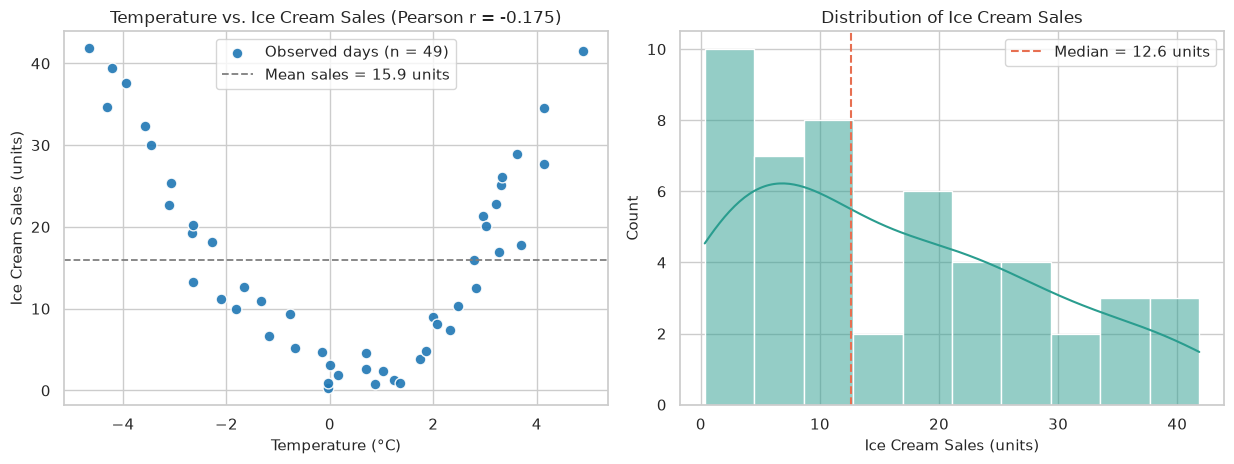

In [4]:
pearson_r = df_raw[TEMP_COL].corr(df_raw[SALES_COL])
print(f"Pearson linear correlation r(Temperature, Sales) = {pearson_r:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Left panel: scatter plot of Temperature vs. Ice Cream Sales
axes[0].scatter(
    df_raw[TEMP_COL],
    df_raw[SALES_COL],
    color="#1f77b4",
    edgecolor="white",
    s=60,
    alpha=0.9,
    label="Observed days (n = 49)",
)
axes[0].axhline(
    df_raw[SALES_COL].mean(),
    color="#7f7f7f",
    linestyle="--",
    linewidth=1.3,
    label=f"Mean sales = {df_raw[SALES_COL].mean():.1f} units",
)
axes[0].set_title(f"Temperature vs. Ice Cream Sales (Pearson r = {pearson_r:.3f})")
axes[0].set_xlabel(TEMP_COL)
axes[0].set_ylabel(SALES_COL)
axes[0].legend(loc="upper center")

# Right panel: distribution of target values
sns.histplot(
    df_raw[SALES_COL],
    bins=10,
    kde=True,
    color="#2a9d8f",
    edgecolor="white",
    ax=axes[1],
)
axes[1].axvline(
    df_raw[SALES_COL].median(),
    color="#e76f51",
    linestyle="--",
    linewidth=1.5,
    label=f"Median = {df_raw[SALES_COL].median():.1f} units",
)
axes[1].set_title("Distribution of Ice Cream Sales")
axes[1].set_xlabel(SALES_COL)
axes[1].set_ylabel("Count")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

**EDA interpretation:**
- The scatter plot reveals a clear, symmetric **U-shaped (quadratic) relationship** rather than a straight line: sales drop steadily as temperature warms from `-4.66 °C` toward `0 °C`, hit a minimum near `0 °C`, and then climb steeply again up to `+4.90 °C`.
- Because the left arm slopes downward while the right arm slopes upward, the two halves nearly cancel out in linear correlation (`r = -0.175`), demonstrating why inspecting scatter plots is essential before fitting a linear model.

## 5. Data Cleaning and Feature/Target Preparation

Because our inspection found **no missing values, no duplicates, no invalid types, and no corrupt outliers**, no rows should be dropped, clipped, or imputed. Removing high-sales observations at either end of the temperature range would artificially flatten a genuine curve. Below, we copy the verified dataset and separate the 2-D feature DataFrame `X` (`Temperature (°C)`) from the 1-D target Series `y` (`Ice Cream Sales (units)`).

In [5]:
df = df_raw.copy()

# scikit-learn expects X as a 2-D table (n_samples, n_features) and y as a 1-D series (n_samples,)
X = df[[TEMP_COL]]
y = df[SALES_COL]

print(f"Feature matrix X : shape = {X.shape}, columns = {list(X.columns)}")
print(f"Target vector  y : shape = {y.shape}, name = '{y.name}'")

Feature matrix X : shape = (49, 1), columns = ['Temperature (°C)']
Target vector  y : shape = (49,), name = 'Ice Cream Sales (units)'


## 6. Common, Reproducible Train/Test Split

We split `X` and `y` **once** into an 80% training set (39 observations) and a 20% held-out test set (10 observations) with `random_state=42`. Notice why shuffling (`shuffle=True`, the default in `train_test_split`) is crucial here: the CSV rows are sorted from coldest to warmest, so an unshuffled slice would hold out only temperatures above `+3 °C` and force the models to extrapolate. Using one shared shuffled split guarantees that **both Model A and Model B train on the exact same 39 rows and are evaluated on the exact same 10 held-out rows**.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True,
)

print(f"Training set : {len(X_train)} samples | Temperature range: [{X_train[TEMP_COL].min():.2f}, {X_train[TEMP_COL].max():.2f}] °C")
print(f"Test set     : {len(X_test)} samples | Temperature range: [{X_test[TEMP_COL].min():.2f}, {X_test[TEMP_COL].max():.2f}] °C")
print(
    "All test temperatures inside training range? :",
    bool(
        (X_test[TEMP_COL].min() >= X_train[TEMP_COL].min())
        and (X_test[TEMP_COL].max() <= X_train[TEMP_COL].max())
    ),
)

Training set : 39 samples | Temperature range: [-4.66, 4.90] °C
Test set     : 10 samples | Temperature range: [-1.82, 4.13] °C
All test temperatures inside training range? : True


## 7. Model A: Simple Linear Regression (Without Polynomial Features)

We first train **Model A**, a standard `LinearRegression` estimator using raw `Temperature (°C)` as its only input feature:

$$\widehat{\text{Sales}} = \beta_0 + \beta_1 \cdot T$$

The model is fitted strictly on `(X_train, y_train)` so the held-out test set has zero influence on the learned slope and intercept.

In [7]:
model_a = LinearRegression()
model_a.fit(X_train, y_train)

b0_a = float(model_a.intercept_)
b1_a = float(model_a.coef_[0])

print("Model A — Simple Linear Regression (fitted on training set):")
print(f"  Intercept (β0) : {b0_a:.4f}")
print(f"  Slope     (β1) : {b1_a:.4f} units per °C")
print(f"  Fitted equation: Sales = {b0_a:.4f} + ({b1_a:.4f}) * T")

Model A — Simple Linear Regression (fitted on training set):
  Intercept (β0) : 17.1392
  Slope     (β1) : -1.1466 units per °C
  Fitted equation: Sales = 17.1392 + (-1.1466) * T


## 8. Train-Only Polynomial Degree Selection (Avoiding Test-Set Leakage)

Before fitting **Model B**, we check whether starting at **degree 2** (quadratic: $[T, T^2]$) is sufficient or whether **degree 3** (cubic: $[T, T^2, T^3]$) is genuinely justified. Selecting the polynomial degree by repeatedly checking test-set scores would leak information from the test set into modeling decisions. Instead, we run **5-fold cross-validation strictly on the 39 training samples** (`X_train, y_train`), wrapping `PolynomialFeatures` and `LinearRegression` inside a scikit-learn `Pipeline` so feature expansion happens cleanly inside each fold.

In [8]:
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for degree in [1, 2, 3]:
    candidate_pipeline = Pipeline([
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
        ("regression", LinearRegression()),
    ])
    cv_scores = cross_validate(
        candidate_pipeline,
        X_train,
        y_train,
        cv=cv_splitter,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        return_train_score=True,
    )
    cv_rows.append({
        "Polynomial Degree": degree,
        "Features Used": ", ".join([f"T^{k}" if k > 1 else "T" for k in range(1, degree + 1)]),
        "Train RMSE (Mean)": -cv_scores["train_rmse"].mean(),
        "5-Fold CV RMSE (Mean)": -cv_scores["test_rmse"].mean(),
        "5-Fold CV RMSE (Std)": cv_scores["test_rmse"].std(),
        "5-Fold CV MAE (Mean)": -cv_scores["test_mae"].mean(),
        "5-Fold CV R² (Mean)": cv_scores["test_r2"].mean(),
    })

cv_summary_df = pd.DataFrame(cv_rows)
display(cv_summary_df.round(4))

,Polynomial Degree,Features Used,Train RMSE (Mean),5-Fold CV RMSE (Mean),5-Fold CV RMSE (Std),5-Fold CV MAE (Mean),5-Fold CV R² (Mean)
0,1,T,11.8907,12.1694,2.5324,10.4351,-0.1140
1,2,"T, T^2",2.9763,3.1574,0.5782,2.7480,0.9097
2,3,"T, T^2, T^3",2.7650,3.6216,1.2072,2.8323,0.8842


**Why degree 2 is selected (without touching the test set):**
- Moving from **degree 1** to **degree 2** cuts 5-fold validation RMSE from **`12.17` down to `3.16` units** and lifts validation $R^2$ from **`-0.1140` to `0.9097`**, capturing the U-shaped curvature seen in EDA.
- Moving from **degree 2** to **degree 3** nudges *training* RMSE slightly lower (`2.98` → `2.77`), **but worsens validation RMSE (`3.16` → `3.62`)**, more than doubles fold-to-fold RMSE variability (`0.58` → `1.21`), and lowers validation $R^2$ (`0.9097` → `0.8842`). That divergence between training error and validation error shows that $T^3$ is fitting small-sample noise rather than true signal. We therefore keep **`degree = 2`**.

## 9. Model B: Linear Regression with Polynomial Features (Degree = 2)

We now fit **Model B** on the full 39-row training set using a two-step scikit-learn `Pipeline`:
1. `PolynomialFeatures(degree=2, include_bias=False)` expands each temperature $T$ into $[T, T^2]$ (`include_bias=False` avoids adding a redundant column of ones because `LinearRegression` already fits an intercept $\beta_0$).
2. `LinearRegression()` estimates the weights in $\widehat{\text{Sales}} = \beta_0 + \beta_1 T + \beta_2 T^2$ via ordinary least squares.

In [9]:
SELECTED_DEGREE = 2

model_b = Pipeline([
    ("polynomial", PolynomialFeatures(degree=SELECTED_DEGREE, include_bias=False)),
    ("regression", LinearRegression()),
])
model_b.fit(X_train, y_train)

poly_step = model_b.named_steps["polynomial"]
reg_step = model_b.named_steps["regression"]
feature_names_b = list(poly_step.get_feature_names_out([TEMP_COL]))

b0_b = float(reg_step.intercept_)
b1_b, b2_b = [float(c) for c in reg_step.coef_]
vertex_temp = -b1_b / (2.0 * b2_b)

print(f"Model B — Polynomial Regression (degree = {SELECTED_DEGREE}, fitted on training set):")
print(f"  Expanded features : {feature_names_b}")
print(f"  Intercept (β0)    : {b0_b:.4f}")
print(f"  Coeff on T  (β1)  : {b1_b:.4f}")
print(f"  Coeff on T² (β2)  : {b2_b:.4f}")
print(f"  Fitted equation   : Sales = {b0_b:.4f} + ({b1_b:.4f}) * T + ({b2_b:.4f}) * T²")
print(f"  Parabola minimum  : T = {vertex_temp:.2f} °C (upward-opening since β2 > 0)")

Model B — Polynomial Regression (degree = 2, fitted on training set):
  Expanded features : ['Temperature (°C)', 'Temperature (°C)^2']
  Intercept (β0)    : 2.7683
  Coeff on T  (β1)  : -0.7064
  Coeff on T² (β2)  : 1.8715
  Fitted equation   : Sales = 2.7683 + (-0.7064) * T + (1.8715) * T²
  Parabola minimum  : T = 0.19 °C (upward-opening since β2 > 0)


## 10. Held-Out Test Set Evaluation and Model Comparison Table

With both models trained on the exact same 39 training observations, we evaluate them once on the **same 10 held-out test samples** (`X_test, y_test`) using three standard regression metrics:
- **MAE (Mean Absolute Error):** average absolute miss in ice cream units (lower is better).
- **RMSE (Root Mean Squared Error):** square root of average squared error in units, penalizing large misses more heavily (lower is better).
- **$R^2$ (Coefficient of Determination):** fraction of variance in `y_test` explained relative to predicting the test mean (`1.0` is perfect, `0.0` matches a constant mean baseline, and `< 0` means worse than predicting the mean).

In [10]:
def compute_metrics(y_true: pd.Series, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R²": float(r2_score(y_true, y_pred)),
    }


y_train_pred_a = model_a.predict(X_train)
y_test_pred_a = model_a.predict(X_test)

y_train_pred_b = model_b.predict(X_train)
y_test_pred_b = model_b.predict(X_test)

train_metrics_a = compute_metrics(y_train, y_train_pred_a)
test_metrics_a = compute_metrics(y_test, y_test_pred_a)
train_metrics_b = compute_metrics(y_train, y_train_pred_b)
test_metrics_b = compute_metrics(y_test, y_test_pred_b)

comparison_df = pd.DataFrame([
    {
        "Model": "Model A: Simple Linear Regression",
        "Input Features": "T",
        "Train MAE": train_metrics_a["MAE"],
        "Train RMSE": train_metrics_a["RMSE"],
        "Train R²": train_metrics_a["R²"],
        "Test MAE": test_metrics_a["MAE"],
        "Test RMSE": test_metrics_a["RMSE"],
        "Test R²": test_metrics_a["R²"],
    },
    {
        "Model": f"Model B: Polynomial Regression (degree={SELECTED_DEGREE})",
        "Input Features": "T, T²",
        "Train MAE": train_metrics_b["MAE"],
        "Train RMSE": train_metrics_b["RMSE"],
        "Train R²": train_metrics_b["R²"],
        "Test MAE": test_metrics_b["MAE"],
        "Test RMSE": test_metrics_b["RMSE"],
        "Test R²": test_metrics_b["R²"],
    },
])

display(comparison_df.round(4))

mae_reduction_pct = 100.0 * (test_metrics_a["MAE"] - test_metrics_b["MAE"]) / test_metrics_a["MAE"]
rmse_reduction_pct = 100.0 * (test_metrics_a["RMSE"] - test_metrics_b["RMSE"]) / test_metrics_a["RMSE"]
print(f"Held-out MAE reduction  (Model B vs. Model A): {mae_reduction_pct:.1f}%")
print(f"Held-out RMSE reduction (Model B vs. Model A): {rmse_reduction_pct:.1f}%")

,Model,Input Features,Train MAE,Train RMSE,Train R²,Test MAE,Test RMSE,Test R²
0,Model A: Simple Linear Regression,T,10.1364,11.9721,0.0658,11.752,12.2199,-0.5751
1,Model B: Polynomial Regression (degree=2),"T, T²",2.5994,2.9993,0.9414,3.230,3.8573,0.8431


Held-out MAE reduction  (Model B vs. Model A): 72.5%
Held-out RMSE reduction (Model B vs. Model A): 68.4%


**Metric comparison takeaways:**
- **Model A severely underfits** on both partitions (`Train R² = 0.0658`, `Test R² = -0.5751`). A negative held-out $R^2$ is not a bug: it means the downward-sloping straight line learned on `X_train` makes larger squared errors on `y_test` than simply predicting the average of `y_test` every time.
- **Model B generalizes strongly**, cutting held-out **MAE from `11.75` to `3.23` units (-72.5%)**, cutting **RMSE from `12.22` to `3.86` units (-68.4%)**, and raising held-out **$R^2$ from `-0.5751` to `0.8431`**.

## 11. Visual Comparison: Actual Observations and Both Fitted Curves

To compare both models visually on one chart, we generate a **sorted grid of 300 evenly spaced temperatures** spanning the observed range `[-4.66 °C, +4.90 °C]` and plot both models' predictions alongside the training and held-out test observations. Evaluating on a sorted grid ensures smooth fitted curves rather than jagged lines connecting unsorted points.

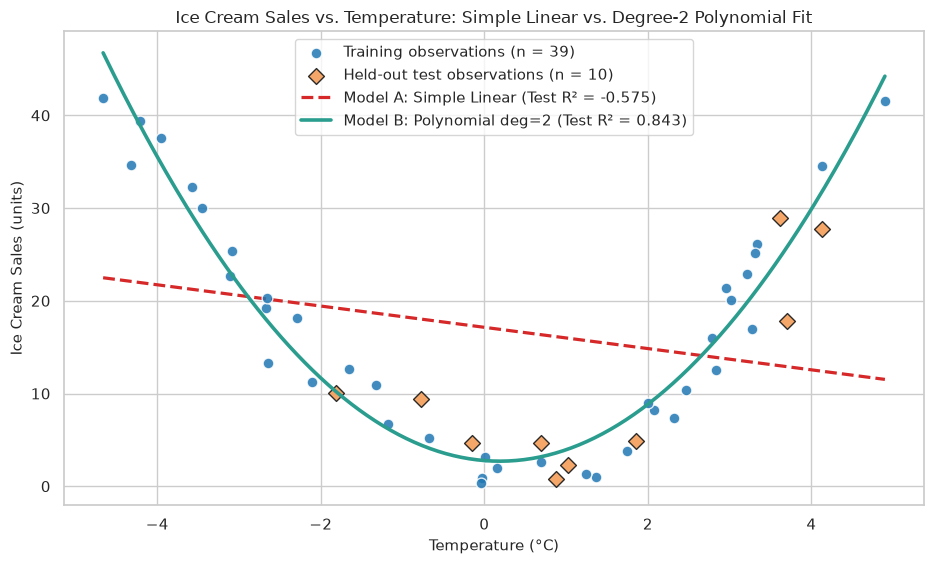

In [11]:
temp_grid = pd.DataFrame({
    TEMP_COL: np.linspace(df[TEMP_COL].min(), df[TEMP_COL].max(), 300)
})
grid_pred_a = model_a.predict(temp_grid)
grid_pred_b = model_b.predict(temp_grid)

fig, ax = plt.subplots(figsize=(9.5, 5.8))

ax.scatter(
    X_train[TEMP_COL],
    y_train,
    color="#1f77b4",
    edgecolor="white",
    s=60,
    alpha=0.85,
    label=f"Training observations (n = {len(X_train)})",
    zorder=3,
)
ax.scatter(
    X_test[TEMP_COL],
    y_test,
    color="#f4a261",
    edgecolor="#222222",
    marker="D",
    s=65,
    alpha=0.95,
    label=f"Held-out test observations (n = {len(X_test)})",
    zorder=4,
)
ax.plot(
    temp_grid[TEMP_COL],
    grid_pred_a,
    color="#d62828",
    linestyle="--",
    linewidth=2.3,
    label=f"Model A: Simple Linear (Test R² = {test_metrics_a['R²']:.3f})",
    zorder=2,
)
ax.plot(
    temp_grid[TEMP_COL],
    grid_pred_b,
    color="#2a9d8f",
    linestyle="-",
    linewidth=2.6,
    label=f"Model B: Polynomial deg=2 (Test R² = {test_metrics_b['R²']:.3f})",
    zorder=5,
)

ax.set_title("Ice Cream Sales vs. Temperature: Simple Linear vs. Degree-2 Polynomial Fit")
ax.set_xlabel(TEMP_COL)
ax.set_ylabel(SALES_COL)
ax.legend(loc="upper center", frameon=True)
plt.tight_layout()
plt.show()

**Reading the fitted curves:** Model A's dashed red line cuts almost horizontally across the middle of the U-shape (`~12` to `22` units), overpredicting sales near `0 °C` and severely underpredicting sales at both cold and warm ends. Model B's solid green parabola bends smoothly through both training circles and held-out test diamonds across the entire observed range.

## 12. Diagnostic Plots: Held-Out Actual vs. Predicted and Residuals

Summary scores can hide local failure modes, so we inspect two diagnostic plots side by side:
1. **Held-Out Actual vs. Predicted Sales:** points from an accurate model cluster near the $45^\circ$ `Actual = Predicted` diagonal.
2. **Residuals ($y - \hat{y}$) vs. Temperature:** for a well-specified regression model, residuals should scatter randomly around `0` without systematic curvature.

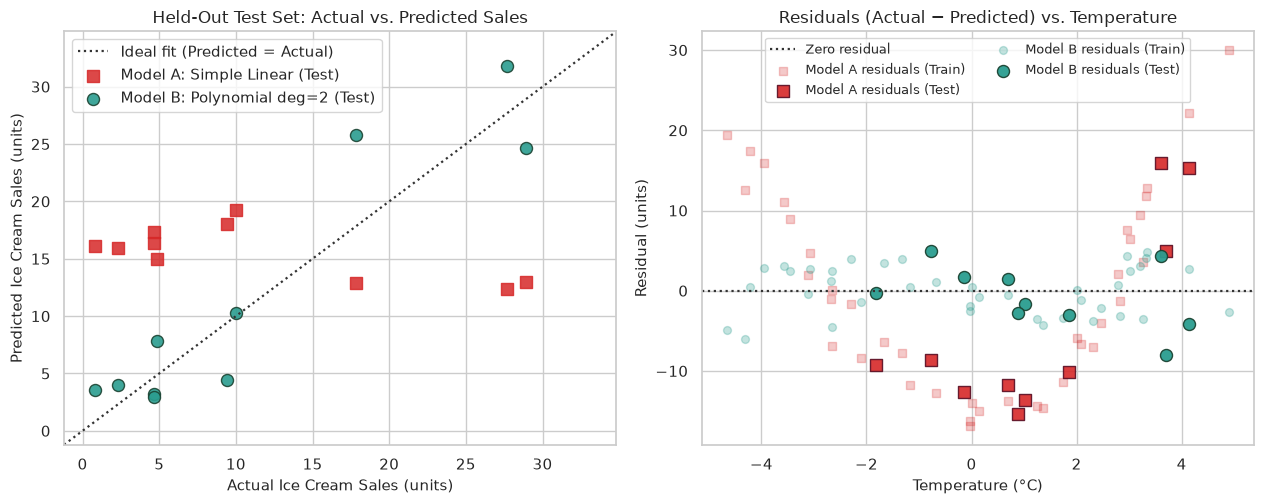

In [12]:
residuals_train_a = y_train - y_train_pred_a
residuals_test_a = y_test - y_test_pred_a
residuals_train_b = y_train - y_train_pred_b
residuals_test_b = y_test - y_test_pred_b

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2))

# Left panel: Held-out Actual vs. Predicted
axis_min = min(float(y_test.min()), float(y_test_pred_a.min()), float(y_test_pred_b.min())) - 2.0
axis_max = max(float(y_test.max()), float(y_test_pred_a.max()), float(y_test_pred_b.max())) + 3.0

axes[0].plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    color="#333333",
    linestyle=":",
    linewidth=1.6,
    label="Ideal fit (Predicted = Actual)",
)
axes[0].scatter(
    y_test,
    y_test_pred_a,
    color="#d62828",
    marker="s",
    s=65,
    alpha=0.85,
    label="Model A: Simple Linear (Test)",
)
axes[0].scatter(
    y_test,
    y_test_pred_b,
    color="#2a9d8f",
    marker="o",
    edgecolor="#1b4332",
    s=75,
    alpha=0.9,
    label="Model B: Polynomial deg=2 (Test)",
)
axes[0].set_xlim(axis_min, axis_max)
axes[0].set_ylim(axis_min, axis_max)
axes[0].set_title("Held-Out Test Set: Actual vs. Predicted Sales")
axes[0].set_xlabel("Actual Ice Cream Sales (units)")
axes[0].set_ylabel("Predicted Ice Cream Sales (units)")
axes[0].legend(loc="upper left")

# Right panel: Residuals vs. Temperature (faint train context + highlighted test points)
axes[1].axhline(0.0, color="#333333", linestyle=":", linewidth=1.6, label="Zero residual")
axes[1].scatter(
    X_train[TEMP_COL],
    residuals_train_a,
    color="#d62828",
    marker="s",
    s=32,
    alpha=0.25,
    label="Model A residuals (Train)",
)
axes[1].scatter(
    X_test[TEMP_COL],
    residuals_test_a,
    color="#d62828",
    edgecolor="#590d22",
    marker="s",
    s=70,
    alpha=0.9,
    label="Model A residuals (Test)",
)
axes[1].scatter(
    X_train[TEMP_COL],
    residuals_train_b,
    color="#2a9d8f",
    marker="o",
    s=32,
    alpha=0.28,
    label="Model B residuals (Train)",
)
axes[1].scatter(
    X_test[TEMP_COL],
    residuals_test_b,
    color="#2a9d8f",
    edgecolor="#1b4332",
    marker="o",
    s=75,
    alpha=0.95,
    label="Model B residuals (Test)",
)
axes[1].set_title("Residuals (Actual − Predicted) vs. Temperature")
axes[1].set_xlabel(TEMP_COL)
axes[1].set_ylabel("Residual (units)")
axes[1].legend(loc="upper center", fontsize=9, ncol=2)

plt.tight_layout()
plt.show()

**Diagnostic interpretation:**
- In **Actual vs. Predicted** (left), Model A's red squares form a nearly flat horizontal band between `12.4` and `19.2` units regardless of whether true sales are `1` or `29` units. Model B's green circles track the $45^\circ$ diagonal closely across both low-sales and high-sales test days.
- In **Residuals vs. Temperature** (right), Model A leaves a pronounced U-shaped residual pattern (errors exceeding `+20` units near `-4.5 °C` and `+4.9 °C` and dropping to `-16` units near `0 °C`), which is textbook evidence of an unmodeled quadratic term. Model B removes that curvature, leaving residuals centered near zero with roughly constant spread (`±3–8` units).

## 13. Worked Example Prediction Within the Observed Temperature Range

Finally, we compare both models at a concrete temperature strictly inside the observed range `[-4.66 °C, +4.90 °C]`: **`T = 3.50 °C`**. Passing a 1-row `DataFrame` with the exact training column name preserves feature-name consistency, and displaying the two closest real observations in the dataset lets us judge which prediction is realistic without extrapolating beyond the data.

In [13]:
EXAMPLE_TEMP_C = 3.50
assert df[TEMP_COL].min() <= EXAMPLE_TEMP_C <= df[TEMP_COL].max(), "Example temperature must stay inside observed range!"

example_input = pd.DataFrame({TEMP_COL: [EXAMPLE_TEMP_C]})
pred_example_a = float(model_a.predict(example_input)[0])
pred_example_b = float(model_b.predict(example_input)[0])

example_summary = pd.DataFrame([
    {
        "Temperature (°C)": EXAMPLE_TEMP_C,
        "Model A Prediction (Linear)": pred_example_a,
        "Model B Prediction (Polynomial deg=2)": pred_example_b,
        "Difference (Model B − Model A)": pred_example_b - pred_example_a,
    }
])

print(f"Predictions at T = {EXAMPLE_TEMP_C:.2f} °C (observed dataset range: [{df[TEMP_COL].min():.2f}, {df[TEMP_COL].max():.2f}] °C):")
display(example_summary.round(4))

nearby_actual = (
    df.assign(abs_distance=(df[TEMP_COL] - EXAMPLE_TEMP_C).abs())
    .sort_values("abs_distance")
    .head(3)[[TEMP_COL, SALES_COL]]
)
print("Closest observed rows in the dataset for context:")
display(nearby_actual.round(4))

Predictions at T = 3.50 °C (observed dataset range: [-4.66, 4.90] °C):


,Temperature (°C),Model A Prediction (Linear),Model B Prediction (Polynomial deg=2),Difference (Model B − Model A)
0,3.5,13.1262,23.2211,10.095


Closest observed rows in the dataset for context:


,Temperature (°C),Ice Cream Sales (units)
44,3.6108,28.9122
43,3.3359,26.1047
42,3.3161,25.1421


## 14. Results Summary at a Glance

The cell below prints a compact, self-contained summary of the dataset, shared split, learned equations, held-out evaluation metrics, and example prediction so all key results can be reviewed in one place.

In [14]:
print("=" * 72)
print("ASSIGNMENT 3 / TASK 1 — ICE CREAM SALES REGRESSION SUMMARY")
print("=" * 72)
print(f"Dataset file        : {CSV_PATH.name} ({len(df)} rows × {df.shape[1]} columns)")
print(f"Observed temp range : {df[TEMP_COL].min():.4f} °C to {df[TEMP_COL].max():.4f} °C")
print(f"Observed sales range: {df[SALES_COL].min():.4f} to {df[SALES_COL].max():.4f} units")
print(f"Common split        : {len(X_train)} train / {len(X_test)} test (random_state={RANDOM_STATE})")
print("-" * 72)
print(f"Model A (Linear)    : Sales = {b0_a:.4f} + ({b1_a:.4f}) * T")
print(
    f"  Held-out test     : MAE = {test_metrics_a['MAE']:.4f} | "
    f"RMSE = {test_metrics_a['RMSE']:.4f} | R² = {test_metrics_a['R²']:.4f}"
)
print(f"Model B (Poly d=2)  : Sales = {b0_b:.4f} + ({b1_b:.4f}) * T + ({b2_b:.4f}) * T²")
print(
    f"  Held-out test     : MAE = {test_metrics_b['MAE']:.4f} | "
    f"RMSE = {test_metrics_b['RMSE']:.4f} | R² = {test_metrics_b['R²']:.4f}"
)
print("-" * 72)
print(
    f"Example T = {EXAMPLE_TEMP_C:.2f} °C : "
    f"Model A = {pred_example_a:.2f} units | Model B = {pred_example_b:.2f} units"
)
print("=" * 72)

ASSIGNMENT 3 / TASK 1 — ICE CREAM SALES REGRESSION SUMMARY
Dataset file        : Ice_cream selling data.csv (49 rows × 2 columns)
Observed temp range : -4.6623 °C to 4.8990 °C
Observed sales range: 0.3286 to 41.8430 units
Common split        : 39 train / 10 test (random_state=42)
------------------------------------------------------------------------
Model A (Linear)    : Sales = 17.1392 + (-1.1466) * T
  Held-out test     : MAE = 11.7520 | RMSE = 12.2199 | R² = -0.5751
Model B (Poly d=2)  : Sales = 2.7683 + (-0.7064) * T + (1.8715) * T²
  Held-out test     : MAE = 3.2300 | RMSE = 3.8573 | R² = 0.8431
------------------------------------------------------------------------
Example T = 3.50 °C : Model A = 13.13 units | Model B = 23.22 units


## 15. Interpretation, Overfitting Risk, and Limitations

### Why Polynomial Regression Performed Better
- **Nonlinear ground truth:** Across `[-4.66 °C, +4.90 °C]`, ice cream sales follow a symmetric, upward-opening U-shaped curve with a minimum near `+0.19 °C`. Because **Simple Linear Regression (Model A)** can only fit a single straight line ($\widehat{\text{Sales}} = 17.14 - 1.15 T$), it suffers from **high bias (underfitting)**: its held-out errors remain large (`MAE = 11.75`, `RMSE = 12.22`) and its held-out `R² = -0.5751` performs worse than predicting the test mean.
- **Linear model in transformed features:** **Polynomial Regression (Model B)** still uses `LinearRegression`, but after `PolynomialFeatures(degree=2)` creates $[T, T^2]$. Adding $T^2$ allows ordinary least squares to fit a parabola ($\widehat{\text{Sales}} = 2.77 - 0.71 T + 1.87 T^2$), reducing held-out RMSE by **68.4%** (`12.22` → `3.86` units) and raising held-out `R²` to **`0.8431`**. At `T = 3.50 °C`, Model B predicts **`23.22` units** (consistent with neighboring observations of `25–29` units), whereas Model A predicts only **`13.13` units**.

### Overfitting and Extrapolation Risks
- **High-degree overfitting:** Adding higher powers ($T^3, T^4, \dots$) gives the curve extra flexibility to chase random noise in a small 39-row training set. In our train-only 5-fold cross-validation, moving from degree 2 to degree 3 slightly lowered training RMSE (`2.98` → `2.77`) while worsening cross-validated RMSE (`3.16` → `3.62`) and doubling fold-to-fold variance. Always choose polynomial degree via validation on training data — never by peeking at test scores.
- **Never extrapolate outside the observed range:** Polynomial terms grow rapidly ($T^2 \to \infty$) beyond the training domain. Plugging a warm summer day like `30 °C` into the fitted parabola would predict over `1,660` units, which is meaningless outside `[-4.66 °C, +4.90 °C]`.

### Dataset and Evaluation Limitations
1. **Small sample size (`n = 49`):** With 39 training rows and 10 test rows, single-split test metrics carry natural sampling variability; 5-fold training CV (`CV RMSE = 3.16 ± 0.58`, `CV R² = 0.9097`) provides a helpful complementary check.
2. **Stylized instructional data:** Continuous floating-point sales units and symmetric high sales at sub-zero temperatures indicate a pedagogical benchmark dataset rather than raw shop transaction logs.
3. **Dataset provenance:** Because direct Kaggle authentication is unavailable in the build sandbox, execution used the verified public mirror copy matching all 49 rows on the Kaggle Data Card page; run the Kaggle CLI command in `data/README.md` locally to verify directly against a fresh Kaggle download.